# Tests Simulations TDV
```Authors: Paul Alvarez updated: 20261010```


El presente notebook explora el uso de .fits simulados para mediciones ground truth de referencia y separar el efecto/rendimiento del algoritmo Total Deep Variation (TDV) propuesto por Kobler et. al.

## Setup

In [1]:
import sys
import os
root_path = os.path.abspath(os.path.join('..'))
if root_path not in sys.path: sys.path.append(root_path)

In [ ]:
from astropy.table import Table
from astropy.io import fits
import matplotlib.pyplot as plt
from photutils.datasets import make_model_image
from astropy.modeling.models import Gaussian2D, make_model_image, make_model_params
import numpy as np
import matplotlib.pyplot as plt
import tifffile
from skimage.metrics import structural_similarity as ssim
from notebooks.utils import plot_results, test_astro, minimax_norm, minimax_unnorm, add_poisson_noise
from skimage import data, img_as_float
from astropy.io import fits
from photutils.detection import DAOStarFinder
from photutils.aperture import CircularAperture, aperture_photometry, CircularAnnulus
from astropy.stats import mad_std, sigma_clipped_stats
from astropy.visualization import simple_norm, AsinhStretch, SqrtStretch, LogStretch
from photutils.detection import DAOStarFinder
from tdv.denoise_utils import psnr
from tdv.denoise_utils import apply_vn, check_color, psnr, load_model, denoise_z
from tdv import model
from notebooks.utils import add_gaussian_noise

In [ ]:

shape = (512, 512)
n_stars = 100
seed = 42

model = Gaussian2D()
params = make_model_params(
    shape=shape,
    n_sources=n_stars,
    x_name='x_mean',
    y_name='y_mean',
    amplitude=(500, 8000),      
    x_stddev=(1.9, 2.1),      
    y_stddev=(1.9, 2.1),    
    theta=0.0,                 
    min_separation=15,          
    seed=seed
)

clean_image = make_model_image(
    shape=shape,
    model=model,
    params=params,
    model_shape=(25, 25),
    x_name='x_mean',
    y_name='y_mean'
)

background_level = 100.0
image_with_bg = clean_image + background_level
np.random.seed(seed)
noisy_image = np.random.poisson(image_with_bg).astype(float)

fits.writeto('../data/ground_truth_uniform_300.fits', clean_image, overwrite=True)
fits.writeto('../data/simulated_noisy_uniform_300.fits', noisy_image, overwrite=True)


In [4]:
print(sum(fluxes))
print(len(fluxes))

402635.5575336571
100


In [ ]:
def plot_stars(image, fwhm=2.5, threshold=3.5, radius=6.0, figsize=(10, 10), cmap='gray'):

    image = np.asarray(image, dtype=float)
    _, median, std = sigma_clipped_stats(image, sigma=3)
    sources = None
    if std > 0: sources = DAOStarFinder(fwhm=fwhm, threshold=threshold * std)(image - median)
    

    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(image, origin='lower', cmap=cmap,
              norm=simple_norm(image, 'sqrt', percent=99))
    if sources is not None and len(sources):
        positions = np.column_stack((sources['x_centroid'], sources['y_centroid']))
        CircularAperture(positions, r=radius).plot(ax=ax, color='red', lw=1)
    ax.set_title(f'Stars found: {0 if sources is None else len(sources)}')
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()

In [27]:
def photometry_val(x, img_coords_ref=None, fwhm=2.5, threshold=3.5, radius=6.0, r_in=8, r_out=10):
    if len(x.shape) == 3: x=x[:, :, 0]
    if img_coords_ref is None:img_coords_ref = x

    _, median, std = sigma_clipped_stats(img_coords_ref, sigma=3.0)
    data_bkg_subtracted = img_coords_ref - median

    daofind = DAOStarFinder(fwhm=fwhm, threshold=threshold * std)
    sources = daofind(data_bkg_subtracted)
    positions = np.transpose((sources['x_centroid'], sources['y_centroid']))
    apertures = CircularAperture(positions, r=radius)       
    rings = CircularAnnulus(positions, r_in=r_in, r_out=r_out) 

    phot_df = aperture_photometry(x, [apertures, rings])
    raw_flux = np.array(phot_df['aperture_sum_0'])
    ring_flux = np.array(phot_df['aperture_sum_1'])
    
    ring_flux_per_pix = ring_flux / rings.area
    bias_flux = ring_flux_per_pix * apertures.area
    true_flux = raw_flux - bias_flux

    return true_flux

In [7]:
def residual_val(y_clean, z_noised, x_denoised):
    y_clean, z_noised, x_denoised = map(np.squeeze, (y_clean, z_noised, x_denoised))
    residual = z_noised - x_denoised
    
    corr_matrix = np.corrcoef(residual.ravel(), y_clean.ravel())
    leakage_corr = float(corr_matrix[0, 1])
    res_mean = float(np.mean(residual))
    
    return leakage_corr, res_mean

In [8]:
def plot_flux(fz, fx):
    fz, fx = np.asarray(fz, dtype=float), np.asarray(fx, dtype=float)
    finite = np.isfinite(fz) & np.isfinite(fx)
    fz, fx = fz[finite], fx[finite]
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # flux compt
    ax = axes[0]
    ax.scatter(fz, fx, alpha=0.6, s=20)
    lims = [min(fz.min(), fx.min()), max(fz.max(), fx.max())]
    ax.plot(lims, lims, 'k--', label='y = x (ideal)')
    if fz.size >= 2 and np.ptp(fz) > 0:
        slope, intercept = np.polyfit(fz, fx, 1)
        xs = np.linspace(*lims, 100)
        ax.plot(xs, slope * xs + intercept, 'r-', label=f'regression: slope={slope:.3f}')
    ax.set_xlabel('Flux z (noisy)'); ax.set_ylabel('Flux x (denoised)')
    ax.set_title('Flux per source'); ax.legend()
    

    positive = (fz > 0) & (fx > 0) # mag when flux > 0 only
    ax = axes[1]
    if positive.any():
        mag_z = -2.5 * np.log10(fz[positive])
        mag_x = -2.5 * np.log10(fx[positive])
        ax.scatter(mag_z, mag_x, alpha=0.6, s=20)
        lims_m = [min(mag_z.min(), mag_x.min()), max(mag_z.max(), mag_x.max())]
        ax.plot(lims_m, lims_m, 'k--', label='y = x (ideal)')
        if mag_z.size >= 2 and np.ptp(mag_z) > 0:
            slope_m, intercept_m = np.polyfit(mag_z, mag_x, 1)
            xs_m = np.linspace(*lims_m, 100)
            ax.plot(xs_m, slope_m * xs_m + intercept_m, 'r-', label=f'regression: slope={slope_m:.3f}')
        ax.invert_xaxis(); ax.invert_yaxis()
        ax.legend()
    else:
        ax.text(0.5, 0.5, 'No positive flux pairs', ha='center', transform=ax.transAxes)
    ax.set_xlabel('z magnitude (noisy)'); ax.set_ylabel('Magnitude x (denoised)')
    ax.set_title(f'Magnitude per source ({positive.sum()}/{fz.size} finite pairs)')

    plt.tight_layout()
    plt.show()

In [9]:
# test fits stars
fits_path_clean = os.path.join('..', 'data', 'ground_truth_uniform_300.fits')
fits_path_noisy = os.path.join('..', 'data', 'simulated_noisy_uniform_300.fits')
y_raw = fits.getdata(fits_path_clean, ext=0)
z_raw = fits.getdata(fits_path_noisy, ext=0)
y_norm = minimax_norm(y_raw)
z_norm = minimax_norm(z_raw, img_scale_reference=y_raw)

In [45]:
true_flux_raw = photometry_val(y_raw, fwhm=1.5, threshold=2, radius=10, r_in=15, r_out=20)
print(sum(true_flux_raw))

10027371.874068381


In [57]:
true_flux_raw_z = photometry_val(z_raw, img_coords_ref=y_raw, fwhm=1.5, threshold=2, radius=10, r_in=15, r_out=20)
print(sum(true_flux_raw_z))

10053456.935249595


In [48]:
flux_theoretical = 2 * np.pi * fluxes * x_stddevs * y_stddevs

print("Flujo integrado teórico:", flux_theoretical.sum())
print("Suma de píxeles del FITS:", y_raw.sum())
print("Fotometría por aperturas:", true_flux_raw.sum())

Flujo integrado teórico: 10284554.034610704
Suma de píxeles del FITS: 10284553.592422578
Fotometría por aperturas: 10027371.874068383


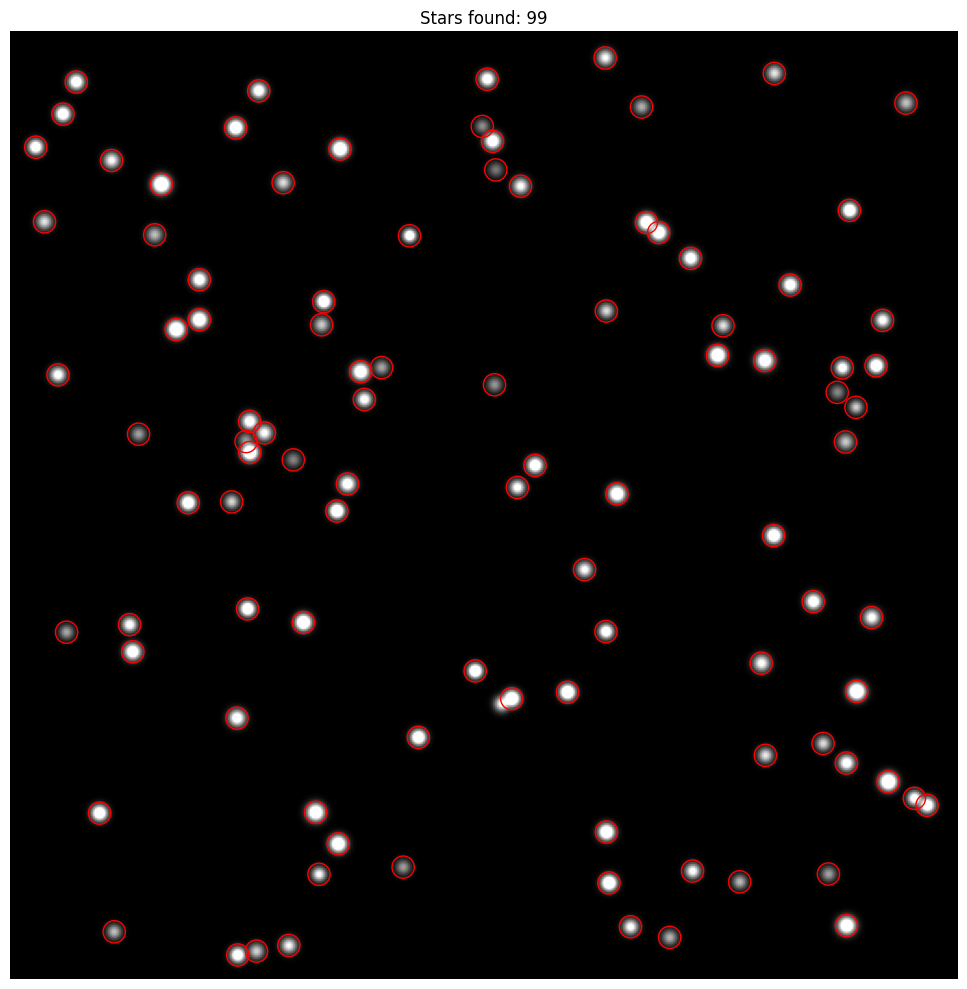

In [54]:
plot_stars(image=y_raw, fwhm=2, threshold=5, radius=6.0)

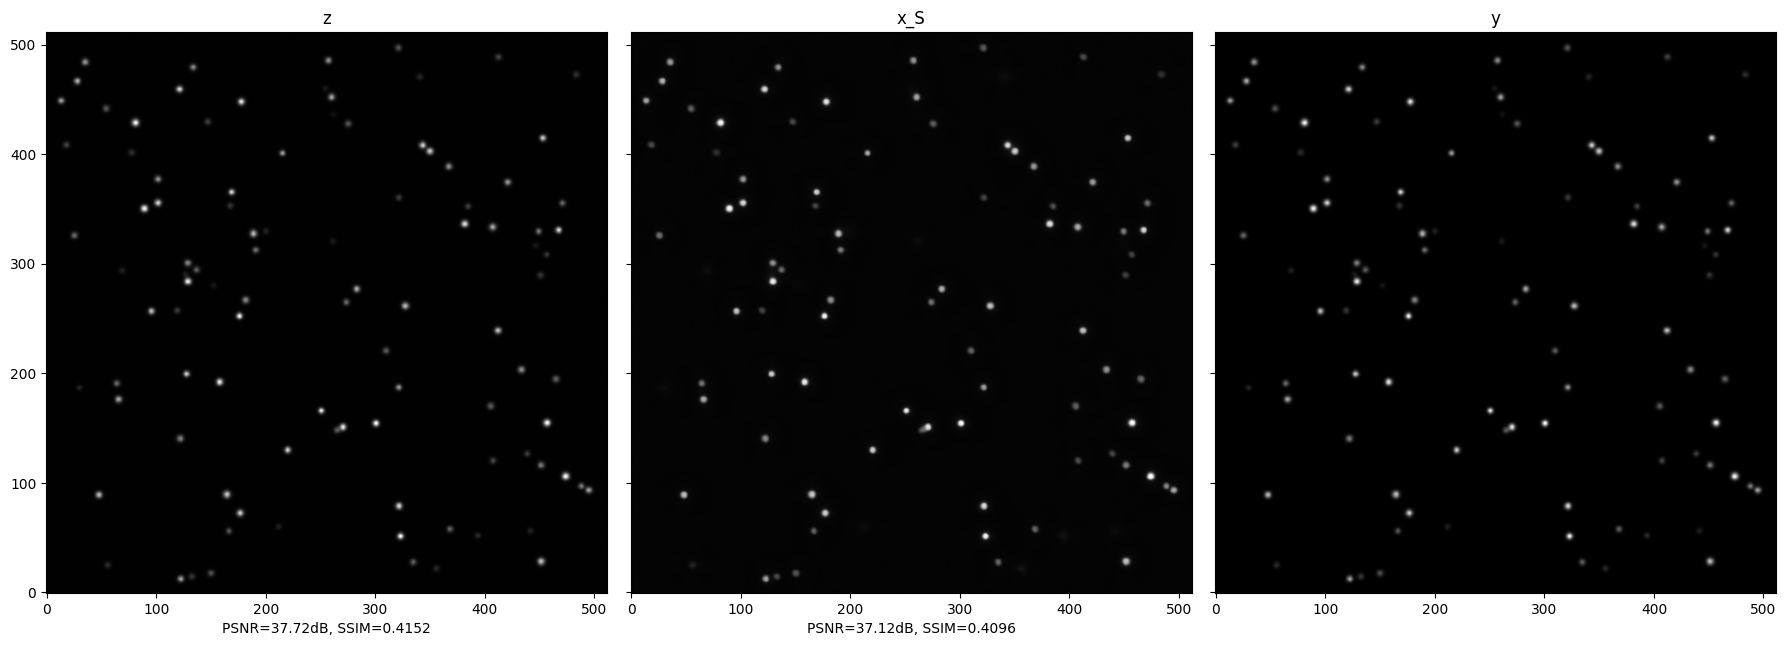

In [12]:
# test noisy img
y_clean, _ = check_color(np.asarray(y_norm, dtype=np.float32))
z_noisy, color = check_color(np.asarray(z_norm, dtype=np.float32))
vn, _ = load_model(color) 
x_denoised = denoise_z(vn=vn, z=z_noisy, scaled=False)
plot_results(z_noisy, x_denoised, y_clean)

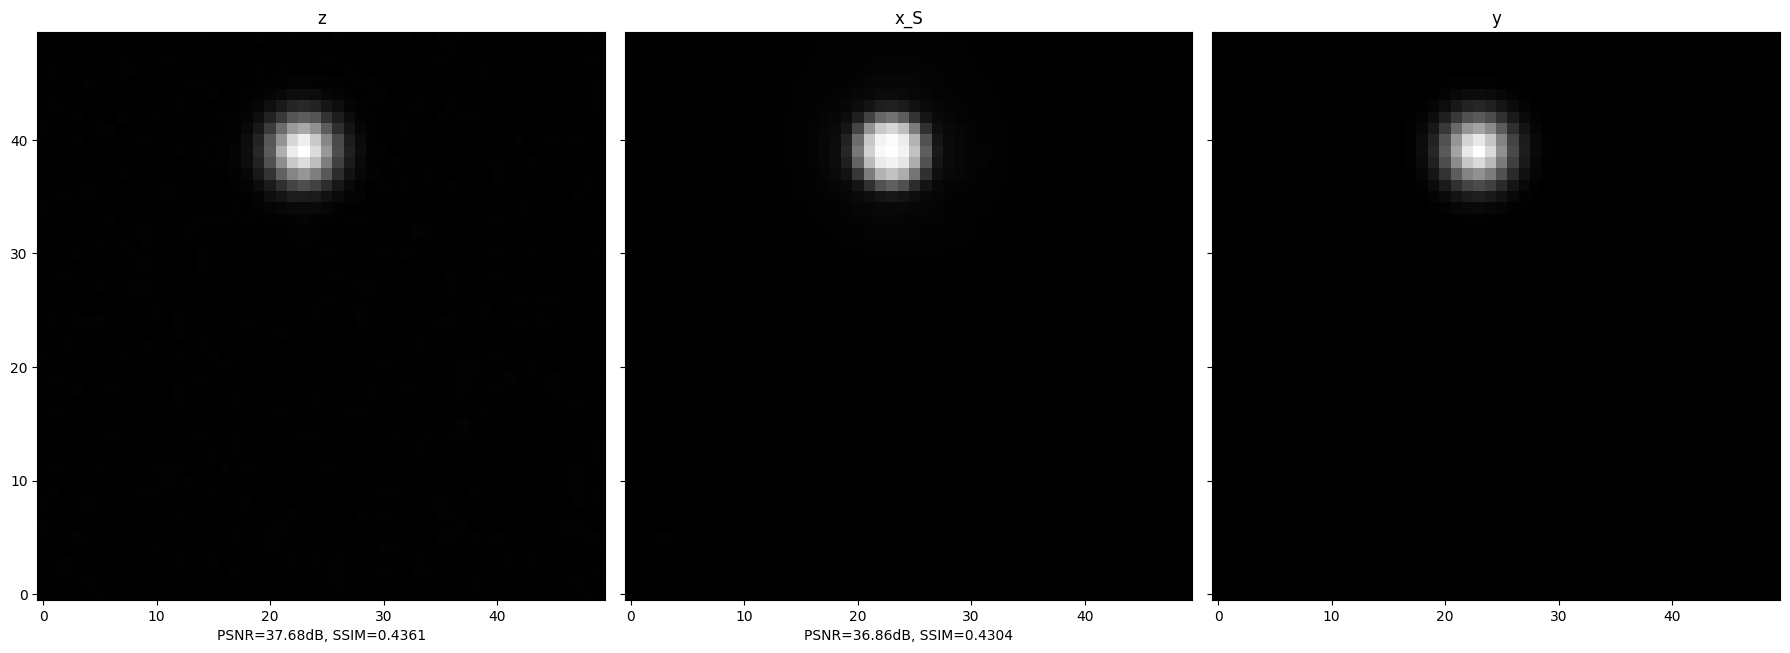

In [34]:
plot_results(z_noisy[50:100, 25:75], x_denoised[50:100, 25:75], y_clean[50:100, 25:75])

corr: 0.2803
residual mean: -0.00000001
Valid sources: 97/100
y (clean) aperture flux: 10120276.673786
z (noisy) aperture flux: 10146187.580202
x (denoised) aperture flux:: 10203411.440609
Ratio z (noisy), y (clean): 1.000455
Ratio x (denoised) , y (clean): 1.012311


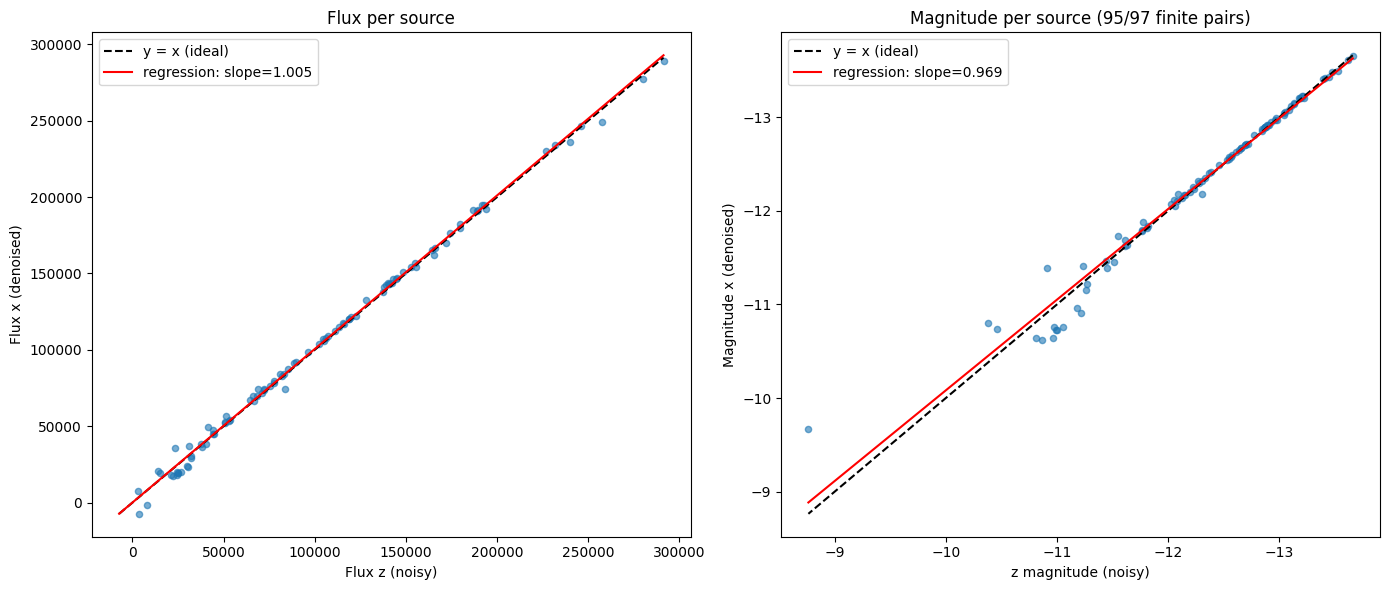

In [60]:
# statistics
leakage_corr, res_mean = residual_val(y_clean, z_noisy, x_denoised)
x_denoised_raw = minimax_unnorm(x_denoised, img_scale_reference=y_raw)
true_flux_z = photometry_val(z_raw, img_coords_ref=y_raw, fwhm=1.5, threshold=2, radius=10, r_in=15, r_out=20)
true_flux_x = photometry_val(x_denoised_raw, img_coords_ref=y_raw, fwhm=1.5, threshold=2, radius=10, r_in=15, r_out=20)
true_flux_y = photometry_val(y_raw, fwhm=1.5, threshold=2, radius=10, r_in=15, r_out=20)
valid_flux = true_flux_y > 0
ratio_zy = true_flux_z[valid_flux] / true_flux_y[valid_flux]
ratio_xy = true_flux_x[valid_flux] / true_flux_y[valid_flux]

print(f'corr: {leakage_corr:.4f}')
print(f'residual mean: {res_mean:.8f}')
print(f"Valid sources: {valid_flux.sum()}/{len(valid_flux)}")
print(f"y (clean) aperture flux: {sum(true_flux_y[valid_flux]):.6f}")
print(f"z (noisy) aperture flux: {sum(true_flux_z[valid_flux]):.6f}")
print(f"x (denoised) aperture flux:: {sum(true_flux_x[valid_flux]):.6f}")
print(f"Ratio z (noisy), y (clean): {np.median(ratio_zy):.6f}")
print(f"Ratio x (denoised) , y (clean): {np.median(ratio_xy):.6f}")
plot_flux(true_flux_z[valid_flux], true_flux_x[valid_flux])

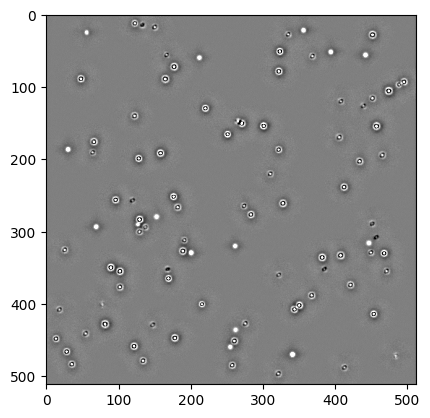

In [62]:
r = z_noisy - x_denoised                                  
vmax = np.percentile(np.abs(r), 99.5)
plt.imshow(r, cmap='gray', vmin=-vmax, vmax=vmax)   # 0 = gris medio